In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from scipy.interpolate import interp1d, CubicSpline

np.random.seed(42)

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")
print("Output directory:", OUTPUT_DIR.resolve())

Libraries imported successfully.
Output directory: C:\Users\user\OneDrive\Documents\Bachelor_Projects\photoacoustic-sensor-reconstruction\outputs


In [2]:
# Physical and simulation parameters
num_sensors = 32
fs = 10e6
num_samples = 600
dt = 1 / fs

c = 1500.0  # Speed of sound (m/s)

source_x = 5e-3
source_y = 20e-3

sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)
sensor_y = 0.0

time = np.arange(num_samples) * dt

# Synthetic photoacoustic signals
signals = np.zeros((num_sensors, num_samples))

pulse_width = 1.5e-6

for i in range(num_sensors):
    distance = np.sqrt(
        (source_x - sensor_x[i])**2 + source_y**2
    )
    arrival_time = distance / c

    signals[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

print("Signal matrix shape:", signals.shape)
print("Number of sensors:", num_sensors)

Signal matrix shape: (32, 600)
Number of sensors: 32


In [3]:
# Image reconstruction grid
x_grid = np.linspace(-10e-3, 10e-3, 100)
y_grid = np.linspace(2e-3, 30e-3, 100)

X, Y = np.meshgrid(x_grid, y_grid)


def reconstruct_das(signal_matrix):
    image = np.zeros_like(X, dtype=float)

    for i in range(num_sensors):
        distance_map = np.sqrt(
            (X - sensor_x[i])**2 + Y**2
        )

        travel_time = distance_map / c
        sample_indices = np.rint(travel_time / dt).astype(int)

        valid = (
            (sample_indices >= 0)
            & (sample_indices < num_samples)
        )

        sampled_signal = np.zeros_like(X, dtype=float)

        sampled_signal[valid] = signal_matrix[
            i, sample_indices[valid]
        ]

        image += sampled_signal

    return image


reference_image = reconstruct_das(signals)

print("Reference image shape:", reference_image.shape)
print("Reference image generated successfully.")

Reference image shape: (100, 100)
Reference image generated successfully.


In [4]:
def calculate_psnr(reference, estimate):
    reference = np.asarray(reference, dtype=float)
    estimate = np.asarray(estimate, dtype=float)

    if reference.shape != estimate.shape:
        raise ValueError("Reference and estimate must have the same shape.")

    data_range = np.max(reference) - np.min(reference)

    if data_range <= 0:
        raise ValueError("Reference image must have a non-zero range.")

    mse = np.mean((reference - estimate) ** 2)

    if mse == 0:
        return float("inf")

    return float(10 * np.log10((data_range**2) / mse))


print(
    "PSNR validation:",
    calculate_psnr(reference_image, reference_image),
    "(expected: infinity)"
)

PSNR validation: inf (expected: infinity)


In [5]:
dropout_counts = [4, 8, 12]

rng = np.random.default_rng(42)
dropout_order = rng.permutation(num_sensors)

results = {
    "reference": "Full-array DAS image",
    "dropout_counts": dropout_counts,
    "inactive_sensor_order": dropout_order.tolist(),
    "psnr_db": {
        "Incomplete": [],
        "Linear": [],
        "Spline": []
    }
}

for n_inactive in dropout_counts:

    inactive_indices = np.sort(dropout_order[:n_inactive])
    active_indices = np.setdiff1d(
        np.arange(num_sensors),
        inactive_indices
    )

    # Simulate inactive sensors
    damaged_signals = signals.copy()
    damaged_signals[inactive_indices, :] = 0.0

    # Reconstruct without interpolation
    incomplete_image = reconstruct_das(damaged_signals)

    # Interpolate missing sensor signals across sensor positions
    linear_signals = damaged_signals.copy()
    spline_signals = damaged_signals.copy()

    linear_interpolator = interp1d(
        sensor_x[active_indices],
        signals[active_indices, :],
        axis=0,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )

    spline_interpolator = CubicSpline(
        sensor_x[active_indices],
        signals[active_indices, :],
        axis=0,
        extrapolate=True
    )

    linear_signals[inactive_indices, :] = (
        linear_interpolator(sensor_x[inactive_indices])
    )

    spline_signals[inactive_indices, :] = (
        spline_interpolator(sensor_x[inactive_indices])
    )

    # Reconstruct images
    linear_image = reconstruct_das(linear_signals)
    spline_image = reconstruct_das(spline_signals)

    # Evaluate against the same reference image
    psnr_incomplete = calculate_psnr(
        reference_image, incomplete_image
    )
    psnr_linear = calculate_psnr(
        reference_image, linear_image
    )
    psnr_spline = calculate_psnr(
        reference_image, spline_image
    )

    results["psnr_db"]["Incomplete"].append(psnr_incomplete)
    results["psnr_db"]["Linear"].append(psnr_linear)
    results["psnr_db"]["Spline"].append(psnr_spline)

    print(f"\nInactive sensors: {n_inactive}/{num_sensors}")
    print(f"Incomplete PSNR: {psnr_incomplete:.2f} dB")
    print(f"Linear PSNR:     {psnr_linear:.2f} dB")
    print(f"Spline PSNR:     {psnr_spline:.2f} dB")


Inactive sensors: 4/32
Incomplete PSNR: 27.30 dB
Linear PSNR:     66.78 dB
Spline PSNR:     87.45 dB

Inactive sensors: 8/32
Incomplete PSNR: 21.34 dB
Linear PSNR:     60.27 dB
Spline PSNR:     85.67 dB

Inactive sensors: 12/32
Incomplete PSNR: 17.66 dB
Linear PSNR:     52.95 dB
Spline PSNR:     74.32 dB


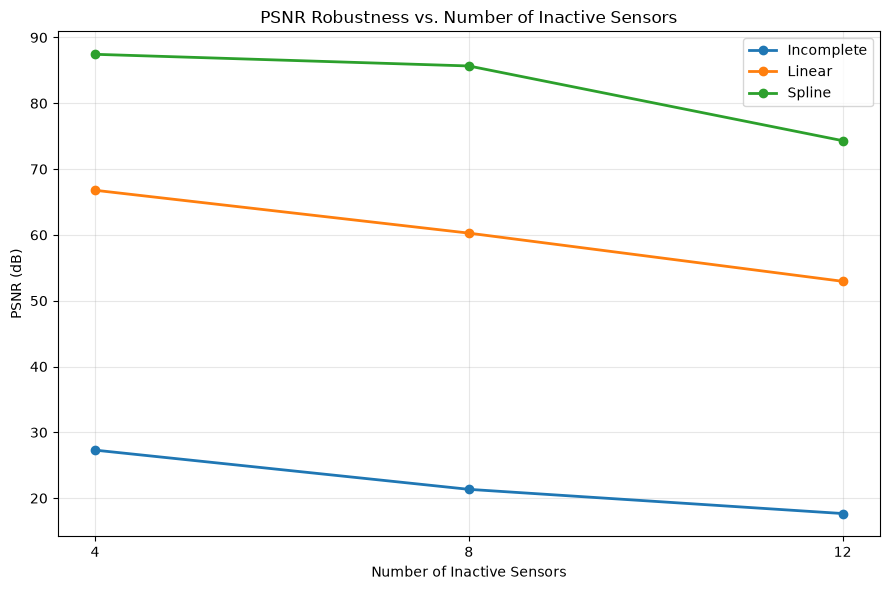

In [6]:
plt.figure(figsize=(9, 6))

for method, values in results["psnr_db"].items():
    plt.plot(
        dropout_counts,
        values,
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Number of Inactive Sensors")
plt.ylabel("PSNR (dB)")
plt.title("PSNR Robustness vs. Number of Inactive Sensors")
plt.xticks(dropout_counts)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "../outputs/day45_psnr_robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
results["inactive_sensor_percentages"] = [
    100 * n / num_sensors for n in dropout_counts
]

with open(
    OUTPUT_DIR / "day45_psnr_robustness_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("Results saved to:", OUTPUT_DIR / "day45_psnr_robustness_results.json")
print("Plot saved to: ../outputs/day45_psnr_robustness.png")

Results saved to: ..\outputs\day45_psnr_robustness_results.json
Plot saved to: ../outputs/day45_psnr_robustness.png
